# Lab 1 — Machine Learning
**Supervised classification on the Iris dataset: KNN vs Logistic Regression**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

RANDOM_STATE = 42
FEATURES = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
LABELS = {"Iris-setosa": 0, "Iris-versicolor": 1, "Iris-virginica": 2}
CLASS_NAMES = list(LABELS.keys())
COLORS = {"Iris-setosa": "#1f77b4", "Iris-versicolor": "#ff7f0e", "Iris-virginica": "#2ca02c"}

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Part 1 — Exploring and Preparing the Iris Dataset

## Exercise 1 — Loading and Inspecting the Dataset
**1.** Load `iris.csv` into a DataFrame.

In [2]:
df = pd.read_csv("data/Iris.csv")

**2.** Display the shape of the DataFrame, its column names and data types, and the first three rows.

In [3]:
print("Shape:", df.shape)
print("\nColumns and data types:")
print(df.dtypes)
# First three rows of the dataset
df.head(3)

Shape: (150, 6)

Columns and data types:
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa


**3.** Display the number of observations and identify the numerical and categorical columns.

In [4]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Number of observations:", len(df))
print("Numerical columns  :", num_cols)
print("Categorical columns:", cat_cols)

Number of observations: 150
Numerical columns  : ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Categorical columns: ['Species']


**4.** Check whether the dataset contains missing values or NaN values. Report the result clearly.

In [5]:
missing = df.isna().sum()
print(missing)
print("\nTotal missing values:", int(missing.sum()))

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Total missing values: 0


**Result:** the dataset contains **no missing or NaN values** in any column, so no imputation or row removal is needed.

## Exercise 2 — Descriptive Statistics and Class Distribution
**5.** Compute the main descriptive statistics of the four numerical features, including count, mean, standard deviation, minimum, maximum and quartiles.

In [6]:
df[FEATURES].describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000,150.000,150.000,150.000
mean,5.843,3.054,3.759,1.199
std,0.828,0.434,1.764,0.763
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


**6.** Determine the number of observations belonging to each Iris species.

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


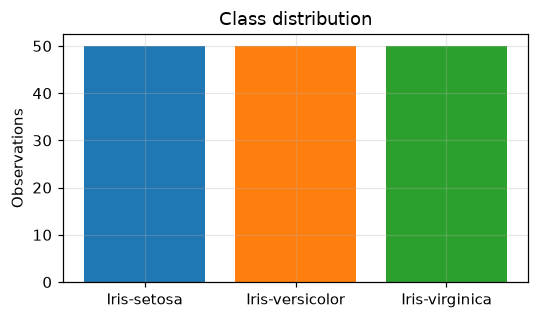

In [7]:
counts = df["Species"].value_counts()
print(counts)

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(counts.index, counts.values, color=[COLORS[s] for s in counts.index])
ax.set_ylabel("Observations")
ax.set_title("Class distribution")
plt.tight_layout(); plt.show()

The dataset is **perfectly balanced**: 50 observations per species. Accuracy is therefore a meaningful metric here (no class dominates).

**7.** Compute the descriptive statistics of the numerical features separately for each species.

In [8]:
df.groupby("Species")[FEATURES].describe().T

Species              Iris-setosa  Iris-versicolor  Iris-virginica
SepalLengthCm count       50.000           50.000          50.000
              mean         5.006            5.936           6.588
              std          0.352            0.516           0.636
              min          4.300            4.900           4.900
              25%          4.800            5.600           6.225
              50%          5.000            5.900           6.500
              75%          5.200            6.300           6.900
              max          5.800            7.000           7.900
SepalWidthCm  count       50.000           50.000          50.000
              mean         3.418            2.770           2.974
              std          0.381            0.314           0.322
              min          2.300            2.000           2.200
              25%          3.125            2.525           2.800
              50%          3.400            2.800           3.000
              75%          3.675            3.000           3.175
              max          4.400            3.400           3.800
PetalLengthCm count       50.000           50.000          50.000
              mean         1.464            4.260           5.552
              std          0.174            0.470           0.552
              min          1.000            3.000           4.500
              25%          1.400            4.000           5.100
              50%          1.500            4.350           5.550
              75%          1.575            4.600           5.875
              max          1.900            5.100           6.900
PetalWidthCm  count       50.000           50.000          50.000
              mean         0.244            1.326           2.026
              std          0.107            0.198           0.275
              min          0.100            1.000           1.400
              25%          0.200            1.200           1.800
              50%          0.200            1.300           2.000
              75%          0.300            1.500           2.300
              max          0.600            1.800           2.500

In [9]:
# Compact view: mean and standard deviation per species
df.groupby("Species")[FEATURES].agg(["mean", "std"]).T

Species             Iris-setosa  Iris-versicolor  Iris-virginica
SepalLengthCm mean        5.006            5.936           6.588
              std         0.352            0.516           0.636
SepalWidthCm  mean        3.418            2.770           2.974
              std         0.381            0.314           0.322
PetalLengthCm mean        1.464            4.260           5.552
              std         0.174            0.470           0.552
PetalWidthCm  mean        0.244            1.326           2.026
              std         0.107            0.198           0.275

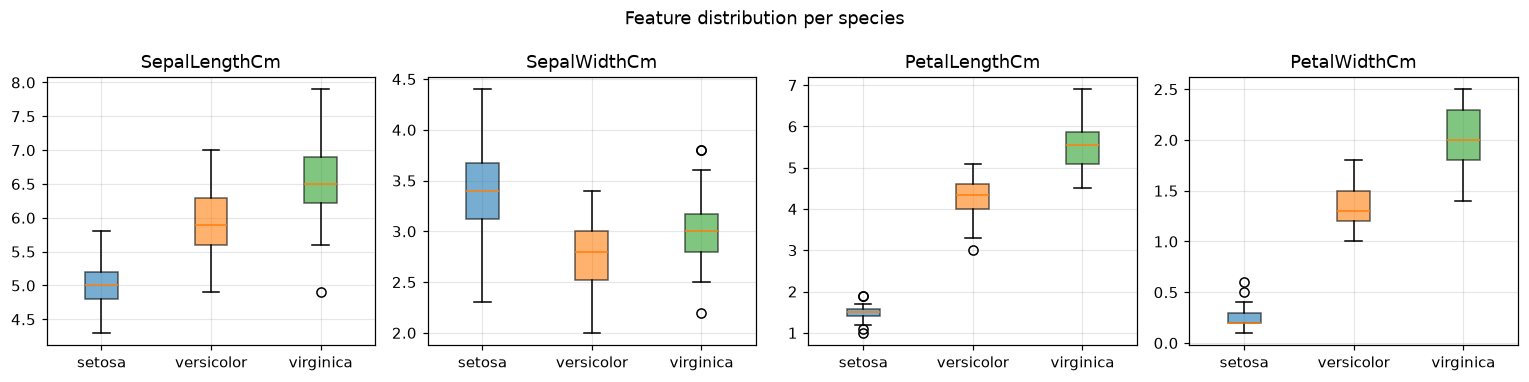

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, feat in zip(axes, FEATURES):
    data = [df.loc[df["Species"] == s, feat] for s in CLASS_NAMES]
    bp = ax.boxplot(data, patch_artist=True)
    ax.set_xticks([1, 2, 3], [s.replace("Iris-", "") for s in CLASS_NAMES])
    for patch, s in zip(bp["boxes"], CLASS_NAMES):
        patch.set_facecolor(COLORS[s]); patch.set_alpha(0.6)
    ax.set_title(feat)
plt.suptitle("Feature distribution per species")
plt.tight_layout(); plt.show()

**8. Briefly comment on which features appear to provide useful information for distinguishing the
species.**

- **PetalLengthCm and PetalWidthCm are the most discriminative.** Setosa has very small petals (length ≈ 1.5 cm, width ≈ 0.25 cm) with no overlap with the other two species. Versicolor (≈ 4.3 / 1.3 cm) and Virginica (≈ 5.6 / 2.0 cm) are also well separated on average, with only a small overlap zone.
- **SepalLengthCm** is moderately useful: the means increase from Setosa (≈ 5.0) to Versicolor (≈ 5.9) to Virginica (≈ 6.6), but the ranges overlap substantially.
- **SepalWidthCm** is the weakest feature: Versicolor and Virginica have very similar distributions; it mainly helps identify Setosa (wider sepals).

Expectation for the models: Setosa should be trivial to classify, while most errors (if any) will come from **Versicolor vs Virginica**.

## Exercise 3 — DataFrame and Numerical Data Manipulation
**9.** Copy the DataFrame and remove `Id`.

In [11]:
df_clean = df.copy()
if "Id" in df_clean.columns:
    df_clean = df_clean.drop(columns="Id")

print("Columns after removing Id:", df_clean.columns.tolist())

Columns after removing Id: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


**10.**  Access the first four cells of the DataFrame using row and column labels.

In [12]:
# First row (label 0), first four columns (the four measurements), selected by label
first_four = df_clean.loc[0, ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]]
print(first_four)

# Same cells, accessed one by one with label-based scalar access
print("\nCell by cell:")
for col in ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]:
    print(f"df_clean.at[0, '{col}'] = {df_clean.at[0, col]}")

SepalLengthCm    5.1
SepalWidthCm     3.5
PetalLengthCm    1.4
PetalWidthCm     0.2
Name: 0, dtype: float64

Cell by cell:
df_clean.at[0, 'SepalLengthCm'] = 5.1
df_clean.at[0, 'SepalWidthCm'] = 3.5
df_clean.at[0, 'PetalLengthCm'] = 1.4
df_clean.at[0, 'PetalWidthCm'] = 0.2


**11-12.** Create a 5 × 5 identity matrix with NumPy and convert it into a SciPy CSR sparse matrix and Display the dense matrix and the corresponding CSR representation.

In [13]:
eye = np.eye(5)
eye_csr = sparse.csr_matrix(eye)

print("Dense matrix:\n", eye)
print("\nCSR representation (row, col) -> value:\n", eye_csr)
print("\nInternal CSR arrays:")
print("  data    =", eye_csr.data)
print("  indices =", eye_csr.indices, " (column index of each stored value)")
print("  indptr  =", eye_csr.indptr, " (row i spans data[indptr[i]:indptr[i+1]])")

Dense matrix:
 [[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]

CSR representation (row, col) -> value:
 <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5 stored elements and shape (5, 5)>
  Coords	Values
  (0, 0)	1.0
  (1, 1)	1.0
  (2, 2)	1.0
  (3, 3)	1.0
  (4, 4)	1.0

Internal CSR arrays:
  data    = [1. 1. 1. 1. 1.]
  indices = [0 1 2 3 4]  (column index of each stored value)
  indptr  = [0 1 2 3 4 5]  (row i spans data[indptr[i]:indptr[i+1]])


The dense matrix stores all 25 values; the CSR format stores only the 5 non-zero values plus their column indices and row pointers. For large, mostly-zero matrices (e.g. one-hot or text features) this saves a lot of memory.

# Part 2 — K-Nearest Neighbors Classification

## Exercise 4 — Preparing Training and Test Data
**13–15.** Features X, target y, and label encoding.

In [14]:
X = df_clean[FEATURES]
y = df_clean["Species"].map(LABELS)

assert y.isna().sum() == 0, "Unexpected species label"
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Encoding:", LABELS)
print("Encoded class counts:", y.value_counts().sort_index().to_dict())

X shape: (150, 4)
y shape: (150,)
Encoding: {'Iris-setosa': 0, 'Iris-versicolor': 1, 'Iris-virginica': 2}
Encoded class counts: {0: 50, 1: 50, 2: 50}


**16–17.** 80/20 split with a fixed `random_state`.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,   # keeps the 1/3 - 1/3 - 1/3 class ratio in both sets
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)
print("\nTest set class counts:", y_test.value_counts().sort_index().to_dict())

X_train: (120, 4)
X_test : (30, 4)
y_train: (120,)
y_test : (30,)

Test set class counts: {0: 10, 1: 10, 2: 10}


120 training / 30 test observations, as expected. `stratify=y` guarantees 10 test samples per species, so the test accuracy is not biased by an unlucky class mix. This split is reused unchanged for every model below.

## Exercise 5 — Building and Evaluating a KNN Classifier (k = 5)

In [16]:
# 18-19: create and train
knn5 = KNeighborsClassifier(n_neighbors=5)
knn5.fit(X_train, y_train)

# 20: predict
y_pred_knn5 = knn5.predict(X_test)

# 21: accuracy
acc_knn5 = accuracy_score(y_test, y_pred_knn5)
print(f"KNN (k=5) test accuracy: {acc_knn5:.4f}  ({int(round(acc_knn5 * len(y_test)))}/{len(y_test)} correct)")

KNN (k=5) test accuracy: 1.0000  (30/30 correct)


**22.** Display a confusion matrix and briefly interpret the classification results.

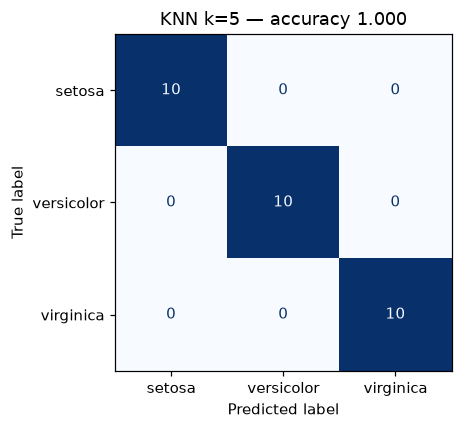

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



In [17]:
cm_knn5 = confusion_matrix(y_test, y_pred_knn5)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm_knn5, display_labels=[c.replace("Iris-", "") for c in CLASS_NAMES]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"KNN k=5 — accuracy {acc_knn5:.3f}")
ax.grid(False)
plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred_knn5, target_names=CLASS_NAMES))

**Interpretation:** with k = 5 the classifier labels **all 30 test flowers correctly** — the confusion matrix is purely diagonal (10/10 for each species). This is consistent with Exercise 2: the petal measurements place the three species in compact, mostly separate regions, so the 5 nearest training neighbours of a test flower almost always share its species.

Caveat: 100 % on 30 samples does not mean the model is perfect — one error would already cost 3.3 points. The test set is small, so this number has a high variance.

## Exercise 6 — Studying the Effect of k
**23–24.** Train and evaluate KNN for k = 1…20 on the same split.

In [18]:
k_values = range(1, 21)
knn_accuracies = {}
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    knn_accuracies[k] = accuracy_score(y_test, model.predict(X_test))

acc_table = pd.DataFrame({"k": list(knn_accuracies), "test_accuracy": list(knn_accuracies.values())})
acc_table.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
k,1.000,2.000,3.0,4.0,5.0,6.000,7.000,8.000,9.0,10.0,11.000,12.000,13.000,14.000,15.000,16.000,17.000,18.000,19.000,20.000
test_accuracy,0.967,0.933,1.0,1.0,1.0,0.967,0.967,0.967,1.0,1.0,0.967,0.967,0.967,0.967,0.967,0.967,0.967,0.967,0.967,0.933


**25.** Create a plot with k on the horizontal axis and test accuracy on the vertical axis.

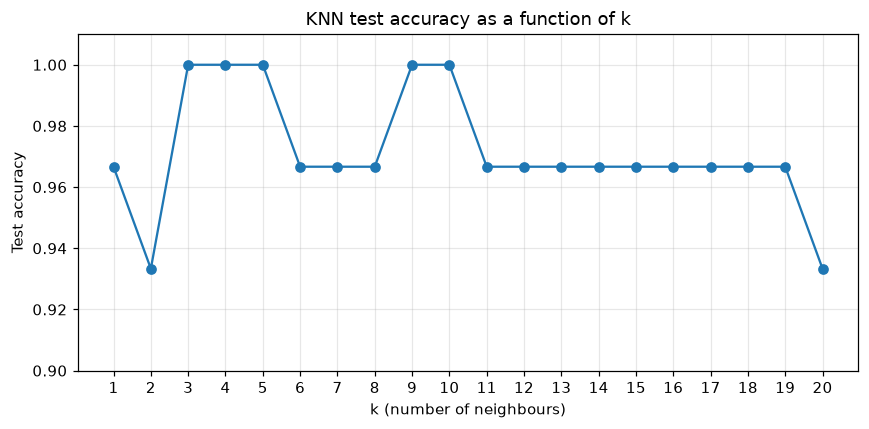

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(acc_table["k"], acc_table["test_accuracy"], marker="o", color="#1f77b4")
ax.set_xticks(list(k_values))
ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("Test accuracy")
ax.set_title("KNN test accuracy as a function of k")
ax.set_ylim(0.90, 1.01)
plt.tight_layout(); plt.show()

**26.** Identify the value of k that gives the highest test accuracy and report the corresponding accuracy.

In [20]:
best_acc = max(knn_accuracies.values())
best_ks = [k for k, a in knn_accuracies.items() if a == best_acc]
best_k = best_ks[0]   # smallest k reaching the maximum accuracy

print(f"Highest test accuracy: {best_acc:.4f}")
print(f"k values reaching it : {best_ks}")
print(f"Selected best k      : {best_k}")

Highest test accuracy: 1.0000
k values reaching it : [3, 4, 5, 9, 10]
Selected best k      : 3


The maximum test accuracy is **1.00 (30/30)**, reached by **k = 3, 4, 5, 9 and 10**. Keeping the smallest such k (simplest model reaching the maximum) gives, **k = 3**, which is retained as the "best KNN" model for Part 4. All other values of k score 0.933–0.967, i.e. only **1 or 2 misclassified test flowers** — the curve is essentially flat.

Note: choosing k with the test set is what the lab asks for, but in a real project k should be chosen by cross-validation on the training set; otherwise the test score becomes optimistic.

**27.** Briefly explain why changing k can affect the performance of KNN.

k controls the **bias–variance trade-off** of the decision boundary:
- **Small k (e.g. k = 1, 2):** the prediction depends on one or two neighbours, so the boundary follows every training point, including noisy ones in the Versicolor/Virginica overlap → high variance, overfitting (here: 1–2 errors at k = 1, 2).
- **Moderate k (3–10):** votes are averaged over several neighbours, which smooths out isolated noisy points while still following the true class structure → best accuracy here.
- **Large k:** the neighbourhood becomes so wide that it spans the boundary between Versicolor and Virginica, and the majority vote drifts toward a coarser decision → higher bias, underfitting (accuracy drops again at k = 20). In the extreme k = n, every point would receive the global majority class.

With an even k, ties between two classes are also possible, which is another reason odd values are usually preferred for small problems.

# Part 3 — Logistic Regression Classification

## Exercise 7 — Visual Exploration
**28-29.** Scatter plot SepalLengthCm vs PetalWidthCm, one marker per species.

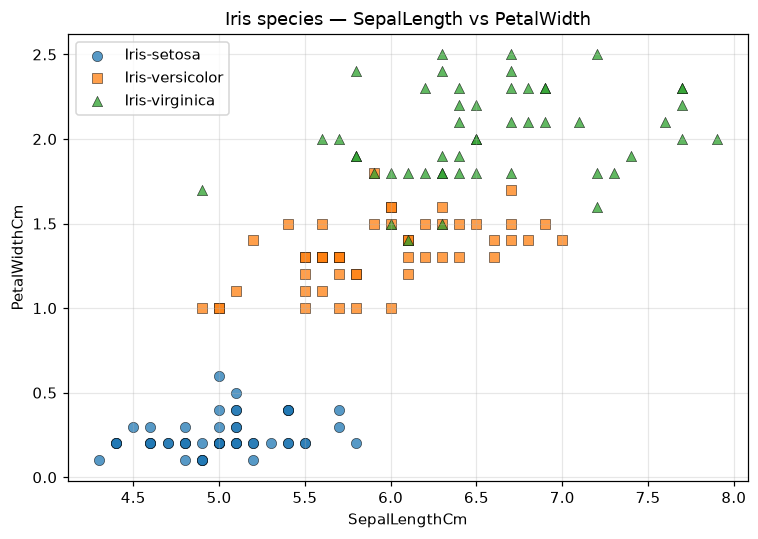

In [21]:
markers = {"Iris-setosa": "o", "Iris-versicolor": "s", "Iris-virginica": "^"}
fig, ax = plt.subplots(figsize=(7, 5))
for species in CLASS_NAMES:
    sub = df_clean[df_clean["Species"] == species]
    ax.scatter(sub["SepalLengthCm"], sub["PetalWidthCm"],
               label=species, marker=markers[species], color=COLORS[species],
               alpha=0.75, edgecolor="k", linewidth=0.4, s=45)
ax.set_xlabel("SepalLengthCm")
ax.set_ylabel("PetalWidthCm")
ax.set_title("Iris species — SepalLength vs PetalWidth")
ax.legend()
plt.tight_layout(); plt.show()

**30. Based on the plot, discuss whether these two features appear sufficient to clearly separate the three
species.**

- **Setosa is clearly and linearly separated** from the other two species: all its petals are narrower than ≈ 0.6 cm, whereas Versicolor and Virginica start at ≈ 1.0 cm. A horizontal line is enough.
- **Versicolor and Virginica are mostly separated along PetalWidth** (≈ 1.0–1.8 cm vs ≈ 1.4–2.5 cm), but there is a visible **overlap zone around PetalWidth ≈ 1.4–1.8 cm**, where Sepal length does not help much since both species share similar values (≈ 5.8–6.7 cm).

**Conclusion:** these two features are sufficient to identify Setosa perfectly, and give a good but not perfect separation of Versicolor vs Virginica. Using all four features (in particular PetalLength) reduces this overlap, which is why the models below use the full feature set.

## Exercise 8 — Logistic Regression Model

**31.** Same X and y, 80/20 split, same fixed `random_state`. Calling `train_test_split` with identical arguments reproduces exactly the same split; this is checked explicitly.

In [22]:
X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

same_split = X_train_lr.index.equals(X_train.index) and X_test_lr.index.equals(X_test.index)
print("Identical split to the KNN part:", same_split)
print("X_train:", X_train_lr.shape, "| X_test:", X_test_lr.shape)

Identical split to the KNN part: True
X_train: (120, 4) | X_test: (30, 4)


Logistic Regression test accuracy: 0.9667  (29/30 correct)


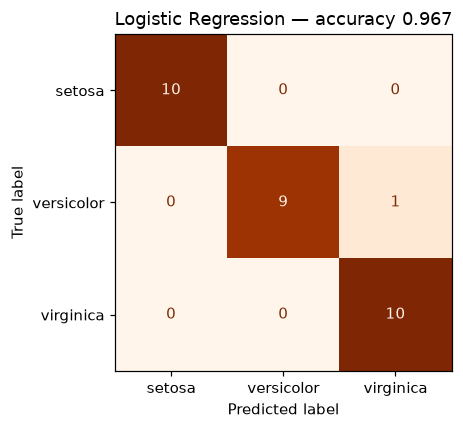

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



In [23]:
# 32: create and train (max_iter raised so the lbfgs solver converges on unscaled features)
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_lr, y_train_lr)

# 33: predict
y_pred_lr = log_reg.predict(X_test_lr)

# 34-35: accuracy + confusion matrix
acc_lr = accuracy_score(y_test_lr, y_pred_lr)
print(f"Logistic Regression test accuracy: {acc_lr:.4f}  ({int(round(acc_lr * len(y_test_lr)))}/{len(y_test_lr)} correct)")

cm_lr = confusion_matrix(y_test_lr, y_pred_lr)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm_lr, display_labels=[c.replace("Iris-", "") for c in CLASS_NAMES]).plot(ax=ax, cmap="Oranges", colorbar=False)
ax.set_title(f"Logistic Regression — accuracy {acc_lr:.3f}")
ax.grid(False)
plt.tight_layout(); plt.show()

print(classification_report(y_test_lr, y_pred_lr, target_names=CLASS_NAMES))

In [24]:
# Which test flower was misclassified?
errors = X_test_lr[y_pred_lr != y_test_lr].copy()
inv = {v: k for k, v in LABELS.items()}
errors["true"] = y_test_lr[y_pred_lr != y_test_lr].map(inv)
errors["predicted"] = [inv[p] for p in y_pred_lr[y_pred_lr != y_test_lr]]
errors

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,true,predicted
77,6.7,3.0,5.0,1.7,Iris-versicolor,Iris-virginica


**35. Result:** Logistic Regression reaches a test accuracy of **0.967 (29/30)**. Setosa and Virginica are classified perfectly; the only error is **one Versicolor flower predicted as Virginica** — a flower lying in the overlap zone identified in Exercises 2 and 7.

# Part 4 — Comparing the Two Classifiers

## Exercise 9 — Performance Comparison
**36.** Create a small comparison table containing the test accuracy of KNN with k = 5, the best KNN
model found in Exercise 6, and Logistic Regression.

In [25]:
best_knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train)
y_pred_best_knn = best_knn.predict(X_test)
acc_best_knn = accuracy_score(y_test, y_pred_best_knn)

comparison = pd.DataFrame({
    "Model": ["KNN (k = 5)", f"Best KNN (k = {best_k})", "Logistic Regression"],
    "Test accuracy": [acc_knn5, acc_best_knn, acc_lr],
    "Correct / 30": [int(round(a * len(y_test))) for a in (acc_knn5, acc_best_knn, acc_lr)],
})
comparison

,Model,Test accuracy,Correct / 30
0,KNN (k = 5),1.000,30
1,Best KNN (k = 3),1.000,30
2,Logistic Regression,0.967,29


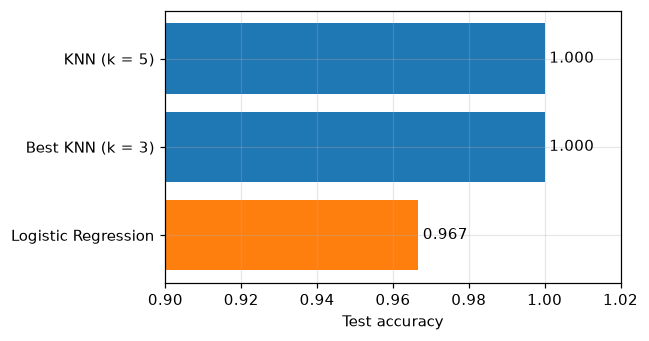

In [26]:
fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.barh(comparison["Model"], comparison["Test accuracy"], color=["#1f77b4", "#1f77b4", "#ff7f0e"])
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xlim(0.9, 1.02)
ax.set_xlabel("Test accuracy")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

**37.** On this train/test split, **KNN gives the highest test accuracy (1.000)**, both with k = 5 and with the best k = 3, ahead of **Logistic Regression (0.967)**. The gap is **exactly one test flower**, so it is not a meaningful difference in general: on 30 samples, the two models should be considered practically equivalent.

**39.** Compare the confusion matrices of the best KNN model and Logistic Regression and identify
which Iris species is the easiest or most difficult to classify.

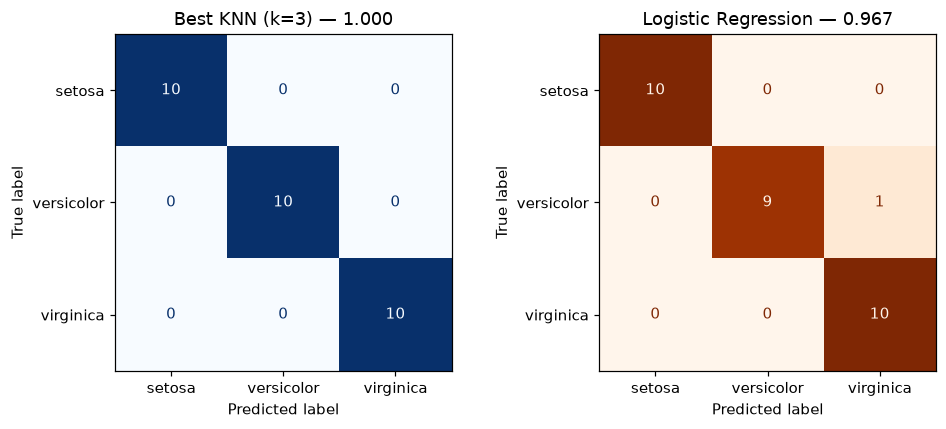

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
short = [c.replace("Iris-", "") for c in CLASS_NAMES]
for ax, cm, title, cmap in [
    (axes[0], confusion_matrix(y_test, y_pred_best_knn), f"Best KNN (k={best_k}) — {acc_best_knn:.3f}", "Blues"),
    (axes[1], cm_lr, f"Logistic Regression — {acc_lr:.3f}", "Oranges"),
]:
    ConfusionMatrixDisplay(cm, display_labels=short).plot(ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(title); ax.grid(False)
plt.tight_layout(); plt.show()

In [28]:
# Per-class recall for each model
per_class = pd.DataFrame({
    f"Best KNN (k={best_k})": confusion_matrix(y_test, y_pred_best_knn).diagonal() / confusion_matrix(y_test, y_pred_best_knn).sum(axis=1),
    "Logistic Regression": cm_lr.diagonal() / cm_lr.sum(axis=1),
}, index=CLASS_NAMES)
per_class.index.name = "Recall per species"
per_class

,Best KNN (k=3),Logistic Regression
Recall per species,,
Iris-setosa,1.0,1.0
Iris-versicolor,1.0,0.9
Iris-virginica,1.0,1.0


- **Easiest species: Iris-setosa.** Both models classify it perfectly (recall 1.0), as predicted by the exploration: its petals are far smaller than those of the other species, so it is linearly separable.
- **Most difficult species: Iris-versicolor** (and, symmetrically, the Versicolor/Virginica boundary). The only error of the whole comparison is a Versicolor predicted as Virginica by Logistic Regression. These two species overlap in petal width/length, so any error is expected to occur there.
- The KNN model has no error on this split; the difference with Logistic Regression comes from a single borderline flower: KNN decides from the local neighbourhood, whereas Logistic Regression must place a **linear** boundary between Versicolor and Virginica, which cannot perfectly follow the overlap zone.

**39.** Write a short conclusion explaining what you learned about data preparation, KNN, the choice of
k, and Logistic Regression.

- **Data preparation:** the Iris dataset is clean (no missing values) and perfectly balanced (50/50/50). The essential steps were removing `Id` (an identifier, which would only add a meaningless "feature"), separating X (4 measurements) from y (encoded species), and creating one reproducible, stratified 80/20 split used by every model so the comparison is fair.
- **Exploration first:** descriptive statistics and plots showed that petal measurements carry most of the information, that Setosa is trivially separable, and that Versicolor vs Virginica is the real difficulty — exactly what the confusion matrices confirmed.
- **KNN:** a simple, non-parametric model that reached 100 % test accuracy with k = 5. It relies on distances, so with features on very different scales, standardisation would be required (here all features are in cm and of similar magnitude).
- **Choice of k:** k controls the bias–variance trade-off. k = 1–2 overfits, a moderate k (3–10) is best, and accuracy starts decreasing for large k (k = 20). Several k tie at 100 %, which shows that on a 30-sample test set the differences are only 1–2 flowers; k should ideally be tuned with cross-validation on the training data, not on the test set.
- **Logistic Regression:** a linear, parametric model that reached 96.7 % (one Versicolor/Virginica error). It is slightly less flexible than KNN at the class boundary, but it is fast, interpretable (one coefficient per feature and class) and outputs class probabilities.
- **Overall:** both classifiers perform very well on Iris; the 1-sample gap is within the noise of a 30-sample test set. A more reliable comparison would use k-fold cross-validation over the whole dataset.